In [1]:
import warnings
# turn off warnings
warnings.filterwarnings('ignore')

# data analysis
import numpy as np
import pandas as pd

# preprocessing
from utils import DataCleanPipleLine
from sklearn.preprocessing import StandardScaler

# viz
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from utils import plotting as plot

# OS
import os
from dotenv import load_dotenv

load_dotenv()

# set theme for the book
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

title_params = {
    'fontsize' : 20,
    'fontweight' : 'bold',
    'color':'grey'
}

In [2]:
# Import the data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = cleaning_pipeline.RunPipeline()


****************************************************************************************************
DF Shape: (253880, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
253879  2026-11-14 12:44:15             13.68  998.734300  62.640624
253880  2026-11-14 12:45:15             13.69  998.722832  62.763670
253881  2026-11-14 12:46:15             13.69  998.696200  62.763670
253882  2026-11-14 12:47:16             13.70  998.730400  62.763670
253883  2026-11-14 12:48:16             13.70  998.631700  62.764650
253884  2026-11-14 12:49:16             13.66  998.643400  62.791992
253885  2026-11-14 12:50:16             13.68  998.620500  62.860350
253886  2026-11-14 12:51:16             13.64  998.666240  62.988280
253887  2026-11-14 12:52:16             13.64  998.613

In [3]:
# import data
file_location2 = os.getenv("F_LOC2")

# run data load
aq_cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location2)

# run pipeline
door_df = aq_cleaning_pipeline.RunPipeline()

****************************************************************************************************
DF Shape: (244711, 6)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity  eCo2  \
244710  2026-11-14 12:44:07             17.05  1000.23348  52.801756   502   
244711  2026-11-14 12:45:07             17.04  1000.24300  52.845704   498   
244712  2026-11-14 12:46:07             17.03  1000.19976  52.811524   495   
244713  2026-11-14 12:47:07             17.07  1000.14350  52.816408   498   
244714  2026-11-14 12:48:08             17.04  1000.13730  52.812500   488   
244715  2026-11-14 12:49:08             17.07  1000.08232  52.837890   494   
244716  2026-11-14 12:50:08             17.04  1000.09300  52.823244   494   
244717  2026-11-14 12:51:08             17.04  1000

In [4]:
# how much missing data do we have?
min_dt = window_df.index.min()
max_dt = window_df.index.max()

# create full date range df
dt_range = pd.date_range(
    start=min_dt,
    end=max_dt,
    freq='1min'
)

dt_range = pd.DataFrame(
    dt_range,
    columns=['date']
)
dt_range.head(5)

,date
0,2026-03-29 20:54:00+00:00
1,2026-03-29 20:55:00+00:00
2,2026-03-29 20:56:00+00:00
3,2026-03-29 20:57:00+00:00
4,2026-03-29 20:58:00+00:00


In [5]:
# merge the dfs together to show missing data
window_full_dt = pd.merge(
    left=dt_range,
    right=window_df,
    left_on='date',
    right_on=window_df.index,
    how='left'
)

window_full_dt.isna().sum()/len(window_df)

date                0.00000
Temperature (oC)    0.00000
Pressure            0.00000
Humidity            0.00000
DateTime            0.23239
Sensor_Status       0.00000
dtype: float64

In [6]:
# merge the dfs together to show missing data

door_full_dt = pd.merge(
    left=dt_range,
    right=door_df,
    left_on='date',
    right_on=door_df.index,
    how='left'
)

door_full_dt.isna().sum()/len(door_df)


date                0.000000
Temperature (oC)    0.030926
Pressure            0.030926
Humidity            0.030926
eCo2                0.030926
VOC                 0.030926
DateTime            0.268174
Sensor_Status       0.030926
dtype: float64

##### Notes

We have a considerable amount of data missing from both dataframe (30% and 35%). The next step is to determine which method is a good approach to impute the data.

The options to explore are:

1. The mean.
2. Interpolation.

In [7]:
# explore the mean and it's impact on the data

missing_data_door_df_stats = door_df.describe()[['Humidity','Temperature (oC)']]
missing_data_window_df_stats= window_df.describe()[['Humidity','Temperature (oC)']]

# take the mean values
door_df_mean_hum, door_df_mean_tmp  = missing_data_door_df_stats.iloc[1].values
window_df_mean_hum, window_df_mean_tmp  = missing_data_window_df_stats.iloc[1].values

# fill in missing data with the mean
window_full_dt['Humidity_mean'] = window_full_dt['Humidity'].fillna(window_df_mean_hum)
window_full_dt['Temperature_mean'] = window_full_dt['Temperature (oC)'].fillna(window_df_mean_tmp)

# show how the data distributions have changed
print("Data with NaN")
print(missing_data_window_df_stats)
print(f"\n")
print("Data with NaN imputed")
print(window_full_dt[['Humidity_mean','Temperature_mean']].describe())

Data with NaN
            Humidity  Temperature (oC)
count  330720.000000     330720.000000
mean       53.479705         19.583042
std         8.550207          2.986980
min        26.669922         13.080000
25%        46.995848         17.120000
50%        54.429688         19.220000
75%        60.597656         21.660000
max        77.616210         29.740000


Data with NaN imputed
       Humidity_mean  Temperature_mean
count  330720.000000     330720.000000
mean       53.479705         19.583042
std         8.550207          2.986980
min        26.669922         13.080000
25%        46.995848         17.120000
50%        54.429688         19.220000
75%        60.597656         21.660000
max        77.616210         29.740000


##### Notes

It appears we have shrunk the distributions for both samples, as we have forced the data closer to the sample mean. The problem with this method is that we have artifically forced the distribution to be thinner (smaller standard deviation) and pull closer to the sample mean. The consequences are underestimated variance (overconfident intervals and tests) and weakened relationships between this feature and the others, since the imputed values carry no information about them.

If the number of missing values was smaller (<5% for example), I wouldn't be too concerned, but because we are dealing with a large amount of missing data, we are effectively altering our sample distribution in a negative way.

In [8]:
# lets try interpolation
window_full_dt.index = window_full_dt['date']
window_full_dt['Humidity_interpolate'] = window_full_dt['Humidity'].interpolate(method='pchip') # we want curives not straight lines
window_full_dt['Temperature_interpolate'] = window_full_dt['Temperature (oC)'].interpolate(method='pchip')

# show how the data distributions have changed
print("Data with NaN")
print(missing_data_window_df_stats)
print(f"\n")
print("Data with NaN imputed")
print(window_full_dt[['Humidity_interpolate','Temperature_interpolate']].describe())

Data with NaN
            Humidity  Temperature (oC)
count  330720.000000     330720.000000
mean       53.479705         19.583042
std         8.550207          2.986980
min        26.669922         13.080000
25%        46.995848         17.120000
50%        54.429688         19.220000
75%        60.597656         21.660000
max        77.616210         29.740000


Data with NaN imputed
       Humidity_interpolate  Temperature_interpolate
count         330720.000000            330720.000000
mean              53.479705                19.583042
std                8.550207                 2.986980
min               26.669922                13.080000
25%               46.995848                17.120000
50%               54.429688                19.220000
75%               60.597656                21.660000
max               77.616210                29.740000


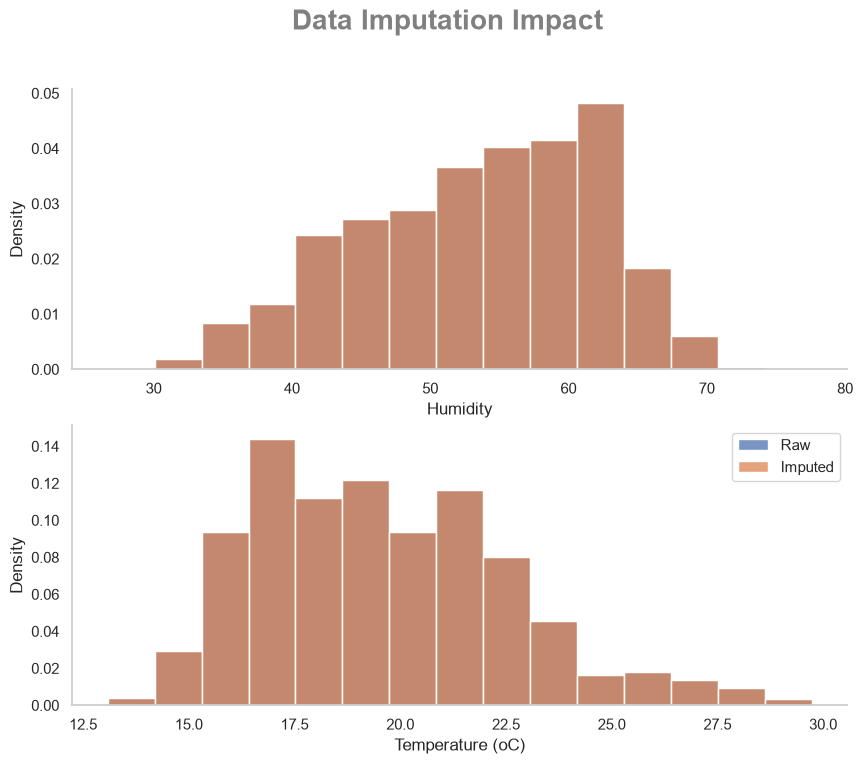

In [9]:
fig, axes = plt.subplots(2,1,figsize=(10,8))
bins=15
for idx, feature in enumerate(['Humidity','Temperature (oC)']):
    sns.histplot(
        data=window_full_dt,
        x=feature,
        stat='density', 
        common_norm=False, 
        bins=bins, 
        label='Raw',
        ax=axes[idx]
    )
    cleanup = "Temperature" if idx == 1 else feature
    sns.histplot(
        data=window_full_dt,
        x=f'{cleanup}_interpolate',
        stat='density', 
        common_norm=False, 
        bins=bins, 
        label='Imputed',
        ax=axes[idx]
    )



plt.legend()

# adjust visual
plot.plot_cleanup(axes, title="Data Imputation Impact")

##### Notes

This method of missing data imputation appears to have minimal effect of the distribution where there is a slight shift in mean and standard deviation, but it is not substantial!

**The shift:**

| Variable    | Statistic | Shift (abs) |
|-------------|-----------|-------------|
| Humidity    | Mean      | ±0.70       |
| Humidity    | Std       | ±0.01       |
| Temperature | Mean      | ±0.03       |
| Temperature | Std       | ±0.04       |

The distributions of both samples show little difference except between 60% and 70% in Humidity, but we can accept this as we will never get a perfect fit and there will be some differences. Therefore, we have established that interpolation preserved the distributions well and will be selected to impute the data.